In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv("../data/processed/train_metadata.csv")
val_metadata = pd.read_csv("../data/processed/val_metadata.csv")
test_metadata = pd.read_csv("../data/processed/test_metadata.csv")

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [3]:
y_val = (val_metadata["Label"] == "Anomaly").astype(int)
y_test = (test_metadata["Label"] == "Anomaly").astype(int)

print("Validation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Validation labels:
Label
1    52953
0     2403
Name: count, dtype: int64

Test labels:
Label
1    52954
0     2403
Name: count, dtype: int64


In [4]:
baseline_model = IsolationForest(
    random_state = 42
)

baseline_model.fit(X_train)

IsolationForest(random_state=42)

In [5]:
baseline_predictions = baseline_model.predict(X_val)

baseline_predictions = (
    baseline_predictions == -1
).astype(int)

In [6]:
cm = confusion_matrix(y_val, baseline_predictions)
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

[[ 2183   220]
 [ 1366 51587]]

True Negatives: 2183
False Positives: 220
False Negatives: 1366
True Positives: 51587


In [7]:
accuracy = accuracy_score(y_val, baseline_predictions)
precision = precision_score(y_val, baseline_predictions)
recall = recall_score(y_val, baseline_predictions)
f1 = f1_score(y_val, baseline_predictions)

balanced_accuracy = balanced_accuracy_score(
    y_val,
    baseline_predictions
)

fpr = fp / (fp + tn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Balanced Accuracy:", balanced_accuracy)
print("False Positive Rate:", fpr)

Accuracy: 0.9713490859166125
Precision: 0.9957534696083541
Recall: 0.974203538987404
F1-score: 0.984860633829706
Balanced Accuracy: 0.9413256563018584
False Positive Rate: 0.09155222638368705


In [8]:
baseline_scores = -baseline_model.decision_function(X_val)

roc_auc = roc_auc_score(
    y_val,
    baseline_scores
)

pr_auc = average_precision_score(
    y_val,
    baseline_scores
)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9645524581629675
PR-AUC: 0.9951903021250628


In [9]:
contamination_values = [
    "auto",
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

In [10]:
contamination_results = []

for contamination in contamination_values:
    
    print("Testing contamination =", contamination)
    
    model = IsolationForest(
        n_estimators = 100,
        contamination = contamination,
        random_state = 42,
        n_jobs = 1
    )
    
    model.fit(X_train)
    
    predictions = model.predict(X_val)
    predictions = (predictions == -1).astype(int)
    
    cm = confusion_matrix(y_val, predictions)
    tn, fp, fn, tp = cm.ravel()
    
    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)
    
    balanced_accuracy = balanced_accuracy_score(
        y_val,
        predictions
    )
    
    fpr = fp / (fp + tn)
    
    scores = -model.decision_function(X_val)
    
    roc_auc = roc_auc_score(y_val, scores)
    pr_auc = average_precision_score(y_val, scores)
    
    contamination_results.append({
        "contamination": contamination,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy,
        "fpr": fpr,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    })

Testing contamination = auto
Testing contamination = 0.001
Testing contamination = 0.005
Testing contamination = 0.01
Testing contamination = 0.02
Testing contamination = 0.05
Testing contamination = 0.1


In [11]:
contamination_df = pd.DataFrame(
    contamination_results
)

contamination_df

contamination_df = contamination_df.sort_values(
    by = "balanced_accuracy",
    ascending = False
)

contamination_df

best_contamination_result = contamination_df.iloc[0]

print(
    "Best contamination:",
    best_contamination_result["contamination"]
)

print(
    "Balanced Accuracy:",
    best_contamination_result["balanced_accuracy"]
)

print(
    "Recall:",
    best_contamination_result["recall"]
)

print(
    "False Positive Rate:",
    best_contamination_result["fpr"]
)

Best contamination: 0.05
Balanced Accuracy: 0.9480160049593362
Recall: 0.9468018809132627
False Positive Rate: 0.05076987099459009


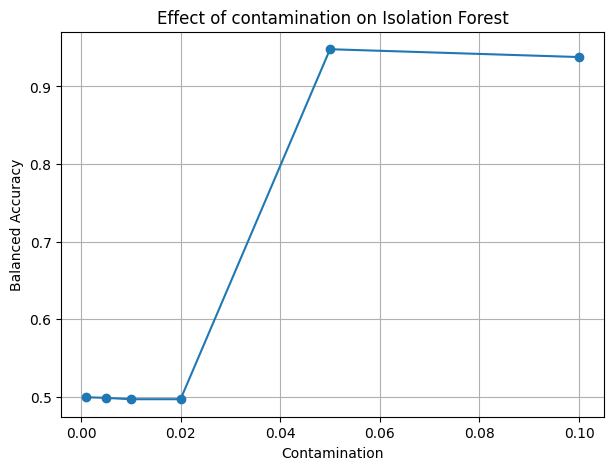

In [12]:
numeric_contamination = contamination_df[
    contamination_df["contamination"] != "auto"
].copy()

numeric_contamination["contamination"] = (
    numeric_contamination["contamination"].astype(float)
)

numeric_contamination = numeric_contamination.sort_values(
    "contamination"
)

plt.figure(figsize=(7,5))

plt.plot(
    numeric_contamination["contamination"],
    numeric_contamination["balanced_accuracy"],
    marker="o"
)

plt.xlabel("Contamination")
plt.ylabel("Balanced Accuracy")
plt.title("Effect of contamination on Isolation Forest")
plt.grid()

plt.show()

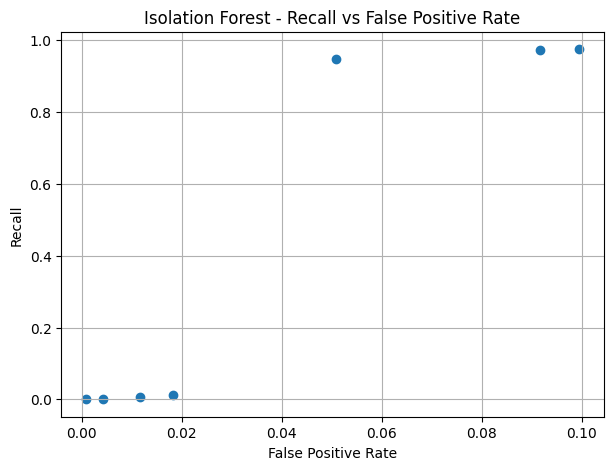

In [13]:
plt.figure(figsize=(7,5))

plt.scatter(
    contamination_df["fpr"],
    contamination_df["recall"]
)

plt.xlabel("False Positive Rate")
plt.ylabel("Recall")
plt.title("Isolation Forest - Recall vs False Positive Rate")
plt.grid()

plt.show()

In [14]:
n_estimators_values = [50, 100, 200, 300]

best_contamination = contamination_df.iloc[0][
    "contamination"
]

print(
    "Selected contamination:",
    best_contamination
)

Selected contamination: 0.05


In [15]:
estimators_results = []

for n_estimators in n_estimators_values:
    
    print(
        "Testing n_estimators =",
        n_estimators
    )

    model = IsolationForest(
       n_estimators = n_estimators,
       contamination = best_contamination,
       random_state = 42,
       n_jobs = -1
    )

    model.fit(X_train)

    predictions = model.predict(X_val)
    predictions = (predictions == -1).astype(int)   

    cm = confusion_matrix(y_val, predictions) 
    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(
      y_val,
      predictions
    )

    recall = recall_score(
      y_val,
      predictions
    )

    f1 = f1_score(
      y_val,
      predictions 
    )

    balanced_accuracy = balanced_accuracy_score(
      y_val,
      predictions
    )

    fpr = fp / (fp + tn)

    scores = -model.decision_function(X_val)

    roc_auc = roc_auc_score(
      y_val,
      scores
    )

    pr_auc = average_precision_score(
      y_val, 
      scores
    )

    estimators_results.append({
      "n_estimators": n_estimators,
      "balanced_accuracy": balanced_accuracy,
      "precision": precision,
      "recall": recall,
      "f1": f1,
      "fpr": fpr,
      "roc_auc": roc_auc,
      "pr_auc": pr_auc
    })

Testing n_estimators = 50
Testing n_estimators = 100
Testing n_estimators = 200
Testing n_estimators = 300


In [16]:
estimators_df = pd.DataFrame(
    estimators_results
)

estimators_df = estimators_df.sort_values(
    by = "balanced_accuracy",
    ascending = False
)

estimators_df

best_estimators = int(
    estimators_df.iloc[0]["n_estimators"]
)

print(
    "Selected n_estimators:",
    best_estimators
)

Selected n_estimators: 100


In [17]:
final_model = IsolationForest(
    n_estimators = best_estimators,
    contamination = best_contamination,
    random_state = 42,
    n_jobs = -1
)

final_model.fit(X_train)

IsolationForest(contamination=0.05, n_jobs=-1, random_state=42)

In [18]:
test_predictions = final_model.predict(X_test)

test_predictions = (
    test_predictions == -1
).astype(int)

test_cm = confusion_matrix(
    y_test,
    test_predictions
)

tn, fp, fn, tp = test_cm.ravel()

print("Confusion Matrix:")
print(test_cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


Confusion Matrix:
[[ 2275   128]
 [ 2739 50215]]

True Negatives: 2275
False Positives: 128
False Negatives: 2739
True Positives: 50215


In [19]:
test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions
)

test_recall = recall_score(
    y_test,
    test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions
)

test_fpr = fp / (fp + tn)

test_scores = -final_model.decision_function(
    X_test
)

test_roc_auc = roc_auc_score(
    y_test,
    test_scores
)

test_pr_auc = average_precision_score(
    y_test,
    test_scores
)    

print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1-score:", test_f1)
print("Balanced Accuracy:", test_balanced_accuracy)
print("False Positive Rate:", test_fpr)
print("ROC-AUC:", test_roc_auc)
print("PR-AUC:", test_pr_auc)

Accuracy: 0.9482088986036094
Precision: 0.9974574419482352
Recall: 0.9482758620689655
F1-score: 0.9722450797215795
Balanced Accuracy: 0.9475045560865011
False Positive Rate: 0.05326674989596338
ROC-AUC: 0.9593723419619798
PR-AUC: 0.9946439919558508


In [20]:
attack_analysis = test_metadata.copy()

attack_analysis["Prediction"] = test_predictions

attack_analysis = attack_analysis[
    attack_analysis["Label"] == "Anomaly"
]

attack_detection = attack_analysis.groupby(
    "Attack_type"   
)["Prediction"].agg(["count", "sum"])

attack_detection["detection_rate"] = (
    attack_detection["sum"] /
    attack_detection["count"]
)

attack_detection

,count,sum,detection_rate
Attack_type,,,
ARP_poisioning,3813,1756,0.460530
DDOS_Slowloris,266,183,0.687970
DOS_SYN_Hping,45045,44465,0.987124
Metasploit_Brute_Force_SSH,18,15,0.833333
NMAP_FIN_SCAN,14,12,0.857143
NMAP_OS_DETECTION,1000,1000,1.000000
NMAP_TCP_scan,501,499,0.996008
NMAP_UDP_SCAN,1292,1281,0.991486
NMAP_XMAS_TREE_SCAN,1005,1004,0.999005


In [21]:
contamination_df.to_csv(
    "../results/tables/isolation_forest_contamination.csv",
    index = False 
)

estimators_df.to_csv(
    "../results/tables/isolation_forest_estimators_results.csv",
    index = False
)

attack_detection.to_csv(
    "../results/tables/isolation_forest_attack_detection.csv",
)